Toy P&L example: OK
BS premium: 2.2872   (expected ~2.2872)

Experiment 1: BS delta hedge, no costs
    N      mean       SE      z      std   DK std   CVaR95
   10    0.0023   0.0014   1.71   0.6051   0.6408   1.4302
   30    0.0007   0.0008   0.89   0.3582   0.3700   0.8341
  100   -0.0002   0.0004  -0.54   0.1991   0.2026   0.4580
  300   -0.0004   0.0003  -1.67   0.1155   0.1170   0.2649
 none    0.0091   0.0077   1.17   3.4566           10.0971
Pass: |z| < 2 (occasionally up to 3), std close to DK, unhedged std ~ 3.35

Experiment 2: BS delta hedge, proportional cost c = 0.001
    N  mean cost  mean P&L      std   CVaR95
   10     0.1960   -0.1937   0.6180   1.6745
   30     0.2732   -0.2725   0.3767   1.1931
  100     0.4191   -0.4193   0.2454   1.0402
  300     0.6521   -0.6525   0.2470   1.2232
Expect: mean cost rising with N while std falls


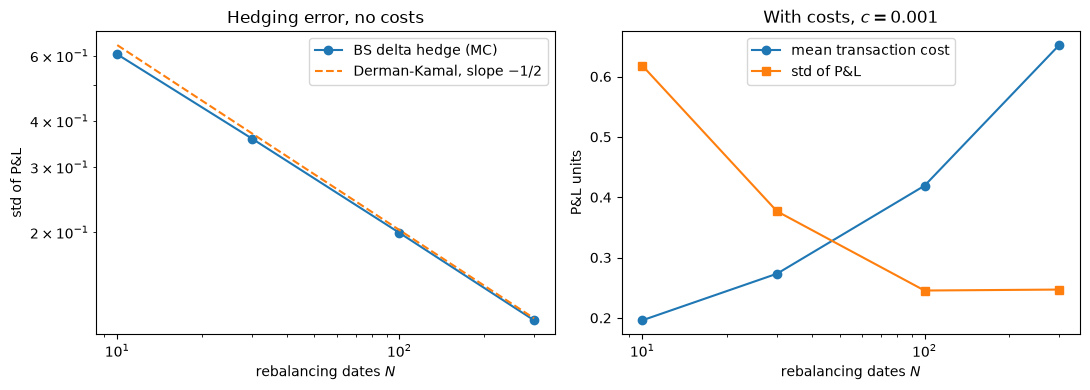

In [1]:
%load_ext autoreload
%autoreload 2

import dataclasses, math, sys
from pathlib import Path

import matplotlib.pyplot as plt
import torch

# make src/ importable from the repo root or from notebooks/
for p in (Path("src"), Path("../src")):
    if p.exists() and str(p.resolve()) not in sys.path:
        sys.path.insert(0, str(p.resolve()))

from bs import bs_call_delta, bs_call_price
from config import Config
from pnl import hedge_pnl
from sim import gbm

N_PATHS = 200_000          # lower to 100_000 if RAM is tight at N = 300
SEED = 1234
N_GRID = [10, 30, 100, 300]
COST = 0.001
OUT_DIR = Path("outputs") if Path("outputs").exists() else Path("../outputs")
OUT_DIR.mkdir(exist_ok=True)


# ---------------- helpers ----------------
def tau_grid(cfg):
    """Times to maturity at t_0..t_{N-1}: shape (N,), from T down to dt."""
    k = torch.arange(cfg.N, device=cfg.device, dtype=cfg.dtype)
    return cfg.T - cfg.dt * k

def bs_premium(cfg):
    S0 = torch.tensor(cfg.S0, device=cfg.device, dtype=cfg.dtype)
    T = torch.tensor(cfg.T, device=cfg.device, dtype=cfg.dtype)
    return bs_call_price(S0, T, cfg.K, cfg.sigma).item()

def summarise(pnl, alpha=0.95):
    """CVaR reported as a POSITIVE expected loss in the worst (1 - alpha) tail."""
    n = pnl.numel()
    k = math.ceil((1 - alpha) * n)
    std = pnl.std()
    return {
        "mean": pnl.mean().item(),
        "se": (std / math.sqrt(n)).item(),
        "std": std.item(),
        "q05": torch.quantile(pnl, 1 - alpha).item(),
        "cvar": (-pnl).topk(k).values.mean().item(),
    }

def derman_kamal_std(cfg):
    sqrt_T = math.sqrt(cfg.T)
    d1 = (math.log(cfg.S0 / cfg.K) + 0.5 * cfg.sigma**2 * cfg.T) / (cfg.sigma * sqrt_T)
    vega = cfg.S0 * math.exp(-0.5 * d1**2) / math.sqrt(2 * math.pi) * sqrt_T
    return math.sqrt(math.pi / 4) * vega * cfg.sigma / math.sqrt(cfg.N)


# ---------------- 1. toy P&L check ----------------
_dt = torch.float64
toy_paths = torch.tensor([[100.0, 102.0, 99.0], [100.0, 102.0, 105.0]], dtype=_dt)
toy_deltas = torch.tensor([[0.5, 0.6], [0.5, 0.6]], dtype=_dt)
for c, expected in {0.01: [0.004, -1.432], 0.0: [1.2, -0.2]}.items():
    got = hedge_pnl(toy_paths, toy_deltas, 2.0, 100.0, c)
    assert torch.allclose(got, torch.tensor(expected, dtype=_dt), atol=1e-10), \
        f"cost={c}: got {got.tolist()}, expected {expected}"
print("Toy P&L example: OK")


# ---------------- 2. benchmark sweep (CPU, float64) ----------------
base = Config(dtype=torch.float64, device=torch.device("cpu"))
premium = bs_premium(base)
print(f"BS premium: {premium:.4f}   (expected ~2.2872)")

rows, unhedged = [], None
for N in N_GRID:
    cfg = dataclasses.replace(base, N=N)
    gen = torch.Generator(device=cfg.device).manual_seed(SEED)
    paths = gbm(cfg, N_PATHS, generator=gen)
    deltas = bs_call_delta(paths[:, :-1], tau_grid(cfg), cfg.K, cfg.sigma)  # no look-ahead

    pnl_0 = hedge_pnl(paths, deltas, premium, cfg.K, 0.0)
    pnl_c = hedge_pnl(paths, deltas, premium, cfg.K, COST)
    if N == 30:
        unhedged = summarise(hedge_pnl(paths, torch.zeros_like(deltas), premium, cfg.K, 0.0))

    rows.append({"N": N, "s0": summarise(pnl_0), "sc": summarise(pnl_c),
                 "cost": (pnl_0 - pnl_c).mean().item(), "dk": derman_kamal_std(cfg)})
    del paths, deltas, pnl_0, pnl_c


# ---------------- 3. tables ----------------
print("\nExperiment 1: BS delta hedge, no costs")
print(f"{'N':>5} {'mean':>9} {'SE':>8} {'z':>6} {'std':>8} {'DK std':>8} {'CVaR95':>8}")
for r in rows:
    s = r["s0"]
    print(f"{r['N']:>5} {s['mean']:>9.4f} {s['se']:>8.4f} {s['mean']/s['se']:>6.2f} "
          f"{s['std']:>8.4f} {r['dk']:>8.4f} {s['cvar']:>8.4f}")
u = unhedged
print(f"{'none':>5} {u['mean']:>9.4f} {u['se']:>8.4f} {u['mean']/u['se']:>6.2f} "
      f"{u['std']:>8.4f} {'':>8} {u['cvar']:>8.4f}")
print("Pass: |z| < 2 (occasionally up to 3), std close to DK, unhedged std ~ 3.35")

print(f"\nExperiment 2: BS delta hedge, proportional cost c = {COST}")
print(f"{'N':>5} {'mean cost':>10} {'mean P&L':>9} {'std':>8} {'CVaR95':>8}")
for r in rows:
    s = r["sc"]
    print(f"{r['N']:>5} {r['cost']:>10.4f} {s['mean']:>9.4f} {s['std']:>8.4f} {s['cvar']:>8.4f}")
print("Expect: mean cost rising with N while std falls")


# ---------------- 4. figure ----------------
Ns = [r["N"] for r in rows]
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))

ax1.loglog(Ns, [r["s0"]["std"] for r in rows], "o-", label="BS delta hedge (MC)")
ax1.loglog(Ns, [r["dk"] for r in rows], "--", label=r"Derman-Kamal, slope $-1/2$")
ax1.set(xlabel="rebalancing dates $N$", ylabel="std of P&L", title="Hedging error, no costs")
ax1.legend()

ax2.semilogx(Ns, [r["cost"] for r in rows], "o-", label="mean transaction cost")
ax2.semilogx(Ns, [r["sc"]["std"] for r in rows], "s-", label="std of P&L")
ax2.set(xlabel="rebalancing dates $N$", ylabel="P&L units", title=f"With costs, $c = {COST}$")
ax2.legend()

fig.tight_layout()
fig.savefig(OUT_DIR / "phase_a_benchmark.png", dpi=150, bbox_inches="tight")
plt.show()